# Classification Artefacts

__This notebook aims to investigate the technical artefacts such as batch effects, plate-out effects (edge effects) on the performance of detecting variants with significant phenotypes across VarChAMP imaging batches.__

In [1]:
import os
import sys
import warnings
from itertools import combinations
from typing import Union
import cupy as cp
import numpy as np
import pandas as pd
import polars as pl
import pyarrow as pa
import pyarrow.parquet as pq
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
from tqdm import tqdm
from tqdm.contrib.concurrent import thread_map
import matplotlib.pyplot as plt
import seaborn as sns
from functools import reduce
import operator

warnings.filterwarnings("ignore")
sys.path.append("..")
from utils import find_feat_cols, find_meta_cols, remove_nan_infs_columns

## define control types
TC = ["EGFP"]
NC = ["RHEB", "MAPK9", "PRKACB", "SLIRP"]
PC = ["ALK", "ALK_Arg1275Gln", "PTK2B"]
cNC = ["Renilla"]
cPC = ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
       "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]

TRN_IMBAL_THRES = 3
MIN_CLASS_NUM = 2
CELL_CHANGES = ["localization", "morphology"]

BATCH_LIST_DICT = {
    "2024_01_23_Batch_7": "2024_02_Batch_7-8", 
    "2024_02_06_Batch_8": "2024_02_Batch_7-8",
    "2024_12_09_Batch_11": "2024_12_Batch_11-12", 
    "2024_12_09_Batch_12": "2024_12_Batch_11-12",
    "2025_01_27_Batch_13": "2025_01_Batch_13-14", 
    "2025_01_28_Batch_14": "2025_01_Batch_13-14",
    "2025_03_17_Batch_15": "2025_03_Batch_15-16", 
    "2025_03_17_Batch_16": "2025_03_Batch_15-16"
}
BIO_PLATE_MAP_BATCHES = ["2024_01_23_Batch_7", "2024_12_09_Batch_11", "2025_01_27_Batch_13", "2025_03_17_Batch_15"]
BIO_BATCHES = ["2024_02_Batch_7-8", "2024_12_Batch_11-12", "2025_01_Batch_13-14", "2025_03_Batch_15-16"]

In [2]:
color_map = {
    'TC': 'slategrey', # Grey for controls
    'NC': 'gainsboro', 
    'PC': 'plum',
    'cPC': 'pink',
    'cNC': 'lightgrey',
    'allele': 'salmon',  # Tomato for disease
    'disease_wt': 'lightskyblue',  # Skyblue for reference
    '': 'white'  # White for missing wells
}

def plot_platemap(
    df,
    plate_name,
    well_pos_col="well_position",
    # this is the column to color by (categorical or continuous)
    value_col="node_type",
    # these columns will be concatenated into the annotation text
    label_cols=("gene_allele",),
    value_type="categorical",   # or "continuous"
    continuous_cmap="vlag",  # matplotlib colormap for continuous mode
    categorical_colors=color_map,     # dict for categorical → color
    grid_square=None
):
    # 1) build empty 16×24 grid
    rows = list("ABCDEFGHIJKLMNOP")
    cols = [f"{i:02d}" for i in range(1,25)]
    plate_grid = (
        pl.DataFrame({c: [""]*16 for c in cols})
          .with_row_index("row_index")
          .unpivot(index="row_index", on=cols, variable_name="col_label", value_name="_")
          .with_columns(
              pl.col("row_index").map_elements(lambda i: rows[i], return_dtype=pl.Utf8).alias("row_label")
          )
    )
    # display(plate_grid)

    # 2) extract row/col from your df’s well_position
    df2 = df.with_columns([
        pl.col(well_pos_col).str.head(1).alias("row_label"),
        pl.col(well_pos_col).str.slice(1).alias("col_label")
    ])

    # 3) join
    plate = plate_grid.join(df2, on=["row_label","col_label"], how="left")

    # 4) pivot out two matrices:
    #    A) data matrix for coloring
    #    B) text matrix for annotation
    # first build annotation text by concatenating label_cols
    plate = plate.with_columns(
        reduce(
            lambda acc, c: acc + "\n" + \
            pl.col(c).round(2).cast(pl.Utf8).fill_null(""),
            label_cols[1:],
            pl.col(label_cols[0]).fill_null("").str.replace_all("_", "\n")
        ).alias("_annot")
    )
    # display(plate)

    # pivot color‐matrix
    data_matrix = plate.pivot(
        index="row_label", on="col_label", values=value_col
    )

    # pivot annotation‐matrix
    annot_matrix = plate.pivot(
        index="row_label", on="col_label", values="_annot"
    ).fill_null("")

    # convert to numpy
    # drop the implicit “row_label” column in position 0
    data = data_matrix[:,1:].to_numpy()
    ann = annot_matrix[:,1:].to_numpy()

    # 5) choose coloring
    if value_type == "categorical":
        if categorical_colors is None:
            raise ValueError("Must supply categorical_colors when value_type='categorical'")
        # map each category in data to its color
        # build vectorized map
        cmap_array = np.vectorize(lambda x: categorical_colors.get(x, "white"))(data)
        # For seaborn we draw a dummy zero‐matrix
        plot_data = np.zeros_like(data, dtype=float)
        cmap = None
    else:
        # continuous: data is numeric
        plot_data = data.astype(float)
        cmap = continuous_cmap
        cmap_array = None

    # 6) plot
    plt.figure(figsize=(35,14))
    ax = sns.heatmap(
        plot_data,
        annot=ann if value_type=="categorical" else None,
        fmt="",
        cmap=cmap,
        cbar=(value_type=="continuous"),
        # linewidths=0,
        # linecolor="white",
        square=True,
        annot_kws={"size":9, "color": "black"}
    )

    # if categorical: overlay colored rectangles
    if value_type=="categorical":
        for i in range(cmap_array.shape[0]):
            for j in range(cmap_array.shape[1]):
                ax.add_patch(plt.Rectangle(
                    (j, i), 1, 1,
                    color=cmap_array[i,j],
                    # ec="black"
                ))
    else:
        # create combined annotation: value + other labels
        # you could easily extend to show gene_allele too by rebuilding ann
        for i in range(ann.shape[0]):
            for j in range(ann.shape[1]):
                txt = ann[i,j]
                # if you want gene_allele too: append "\n"+ann[i,j]
                ax.text(
                    j+0.5, i+0.5, txt,
                    ha="center", va="center", fontsize=9.5, color="black"
                )

    if grid_square is not None:
        grid_sq_mat = plate.pivot(
            index="row_label", on="col_label", values=grid_square
        )[:,1:]#.to_numpy()
        for i in range(grid_sq_mat.shape[0]):
            for j in range(grid_sq_mat.shape[1]):
                if grid_sq_mat[i,j] is not None and grid_sq_mat[i,j]>=1:
                    ax.add_patch(plt.Rectangle(
                        (j, i), 1, 1,
                        linewidth=2, edgecolor="red", facecolor="none"
                    ))

    # 7) finalize axes
    ax.set_title(f"384-Well Plate: {plate_name}")
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.set_xticks(np.arange(len(cols))+0.5)
    ax.set_xticklabels(cols, rotation=0)
    ax.set_yticks(np.arange(len(rows))+0.5)
    ax.set_yticklabels(rows, rotation=0)
    plt.tight_layout()
    plt.show()

    return plate

<Figure size 2400x1600 with 0 Axes>

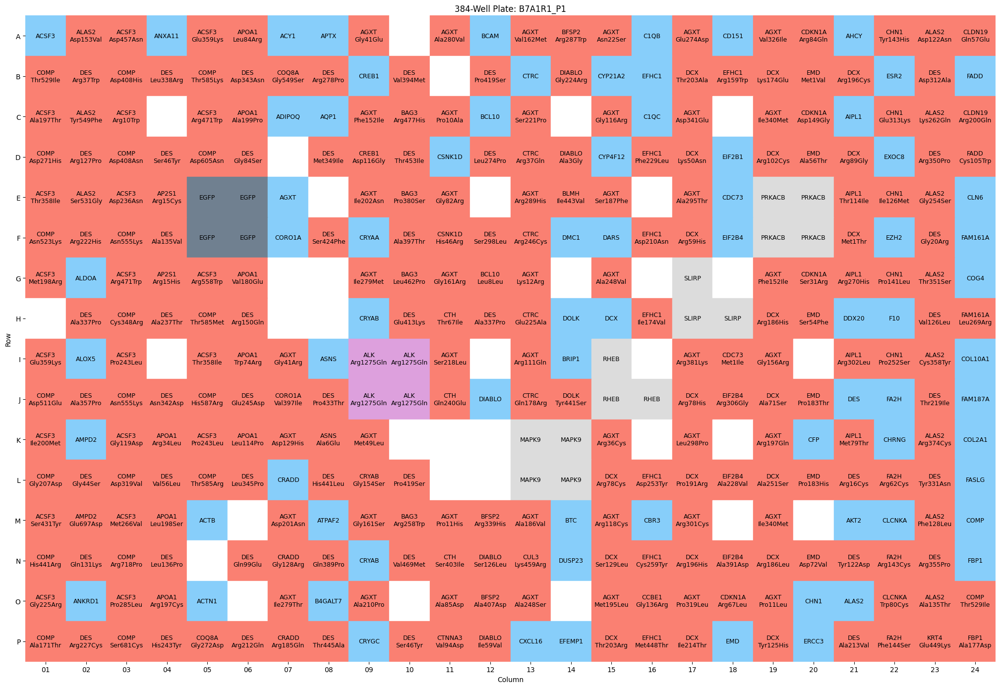

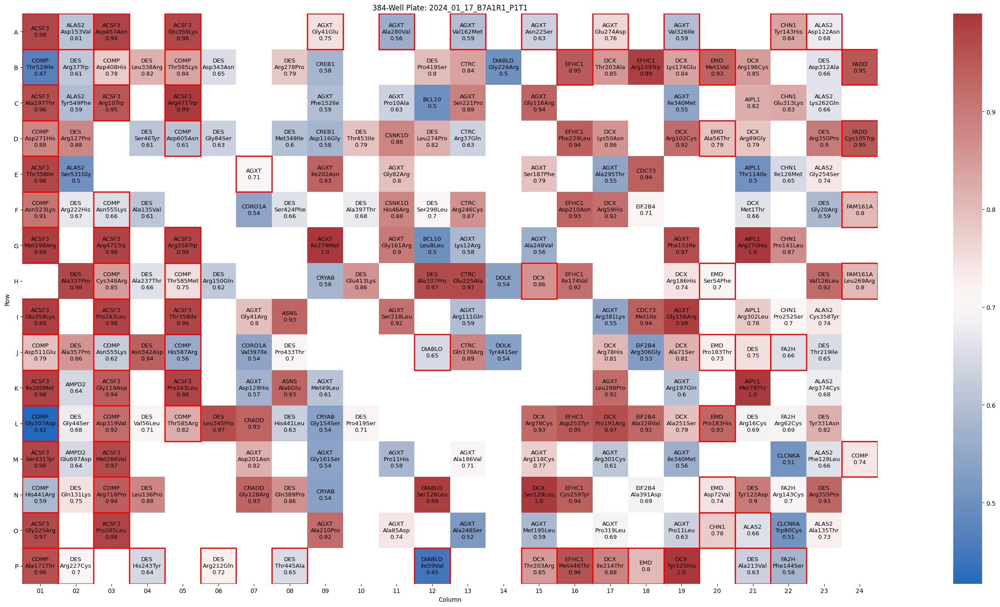

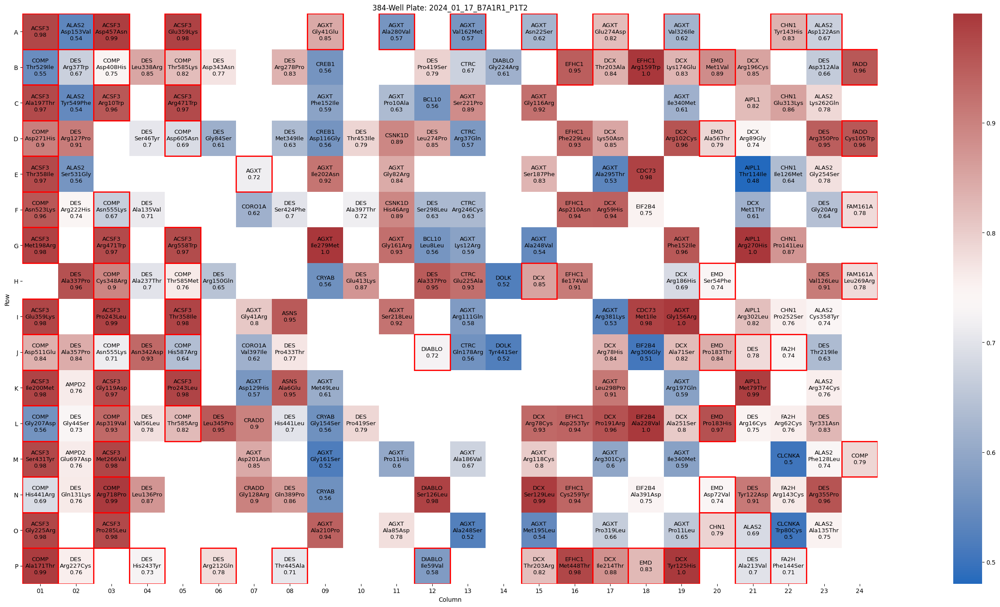

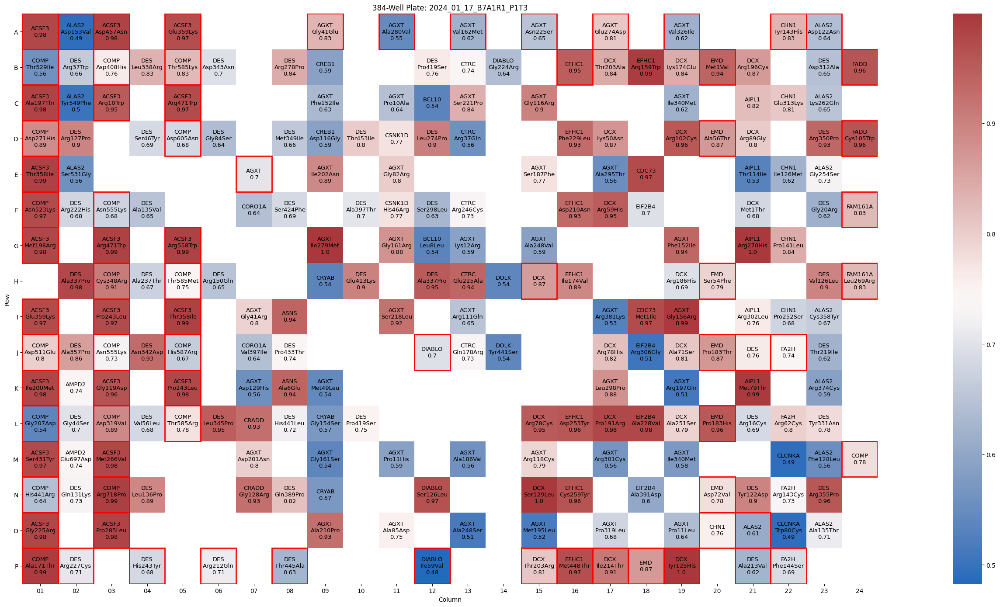

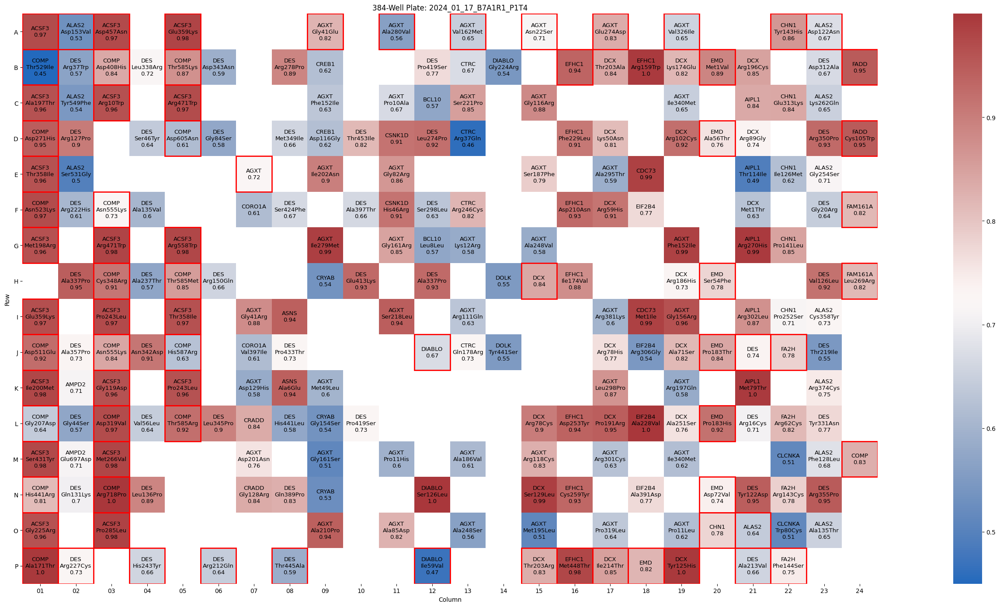

...

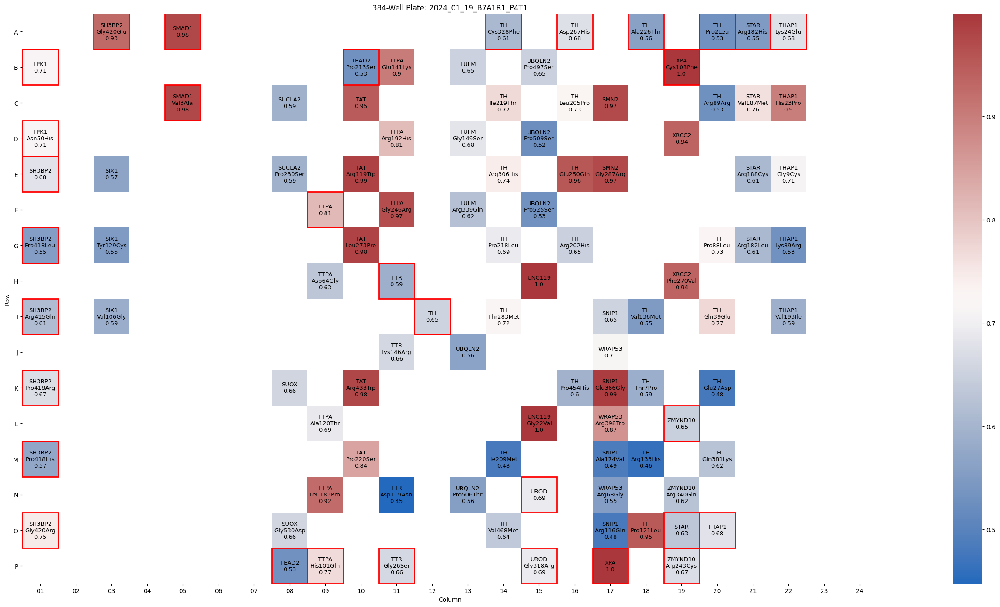

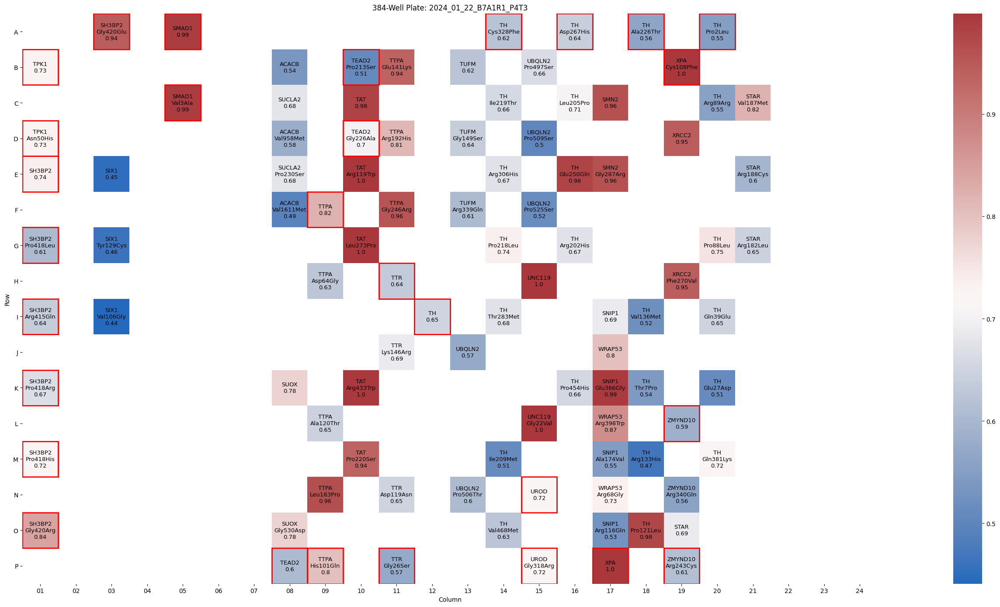

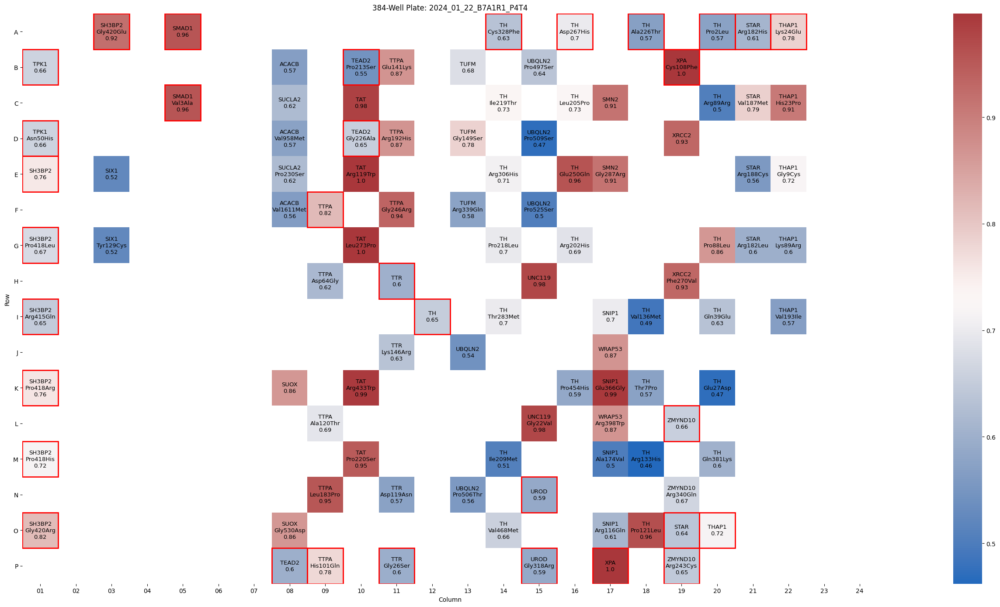

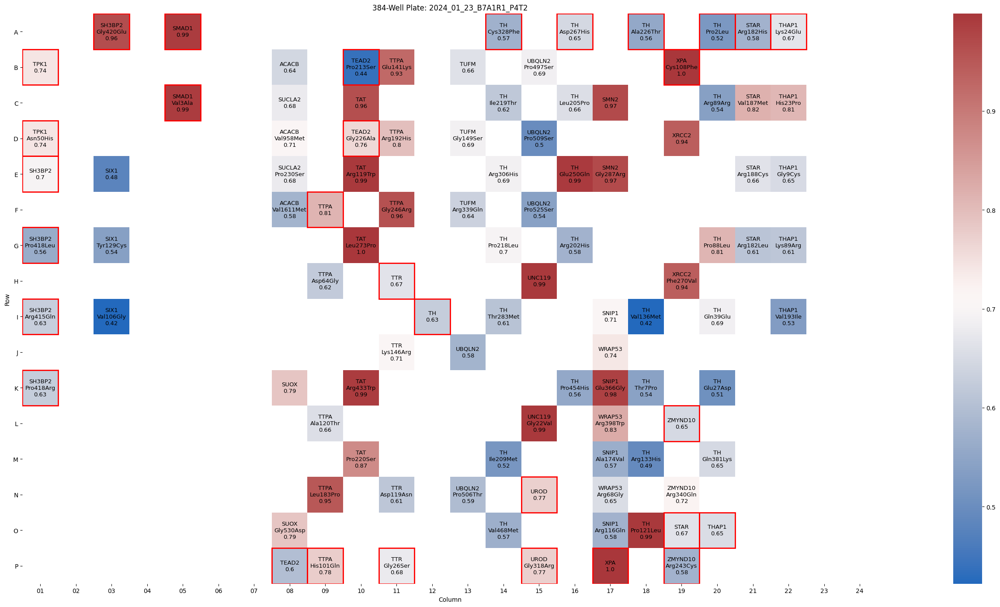

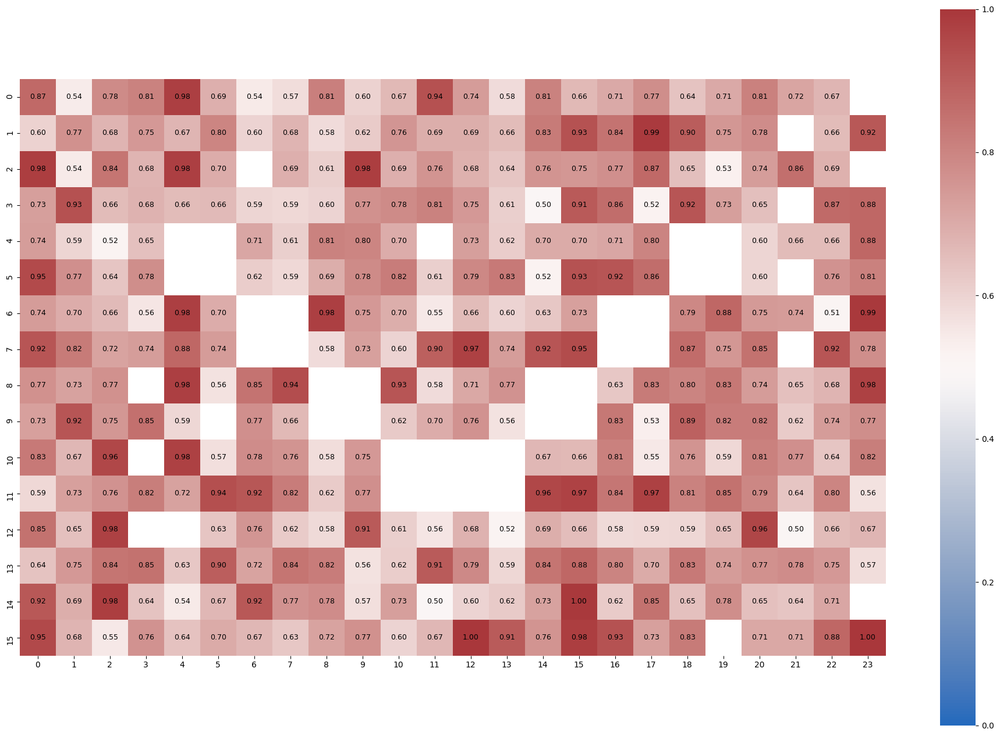

In [128]:
batch_class_met_file = "../outputs/classification_analyses/{}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells/metrics.csv"
profiled_ctrls_df, profiled_ctrls_pass_qc_df = pl.DataFrame(), pl.DataFrame()
profiled_prot_classifiers_df, profiled_morph_classifiers_df = pl.DataFrame(), pl.DataFrame()

plt.clf()
for batch, batch_biorep in zip(BIO_PLATE_MAP_BATCHES, BIO_BATCHES):
    profiled_ctrls_df_batch = pl.DataFrame()
    batch_met_array = []
    platemap_dir = f"../inputs/metadata/platemaps/{batch}/platemap"
    metric_df = pl.read_csv(batch_class_met_file.format(batch)).with_columns(
        pl.when((pl.col("well_0").str.contains(r"(?:01|P|A|24)"))|(pl.col("well_1").str.contains(r"(?:01|P|A|24)")))
        .then(pl.lit(True))
        .otherwise(pl.lit(False))
        .alias("Well_On_Edge")
    )
    ## load the img qc results
    allele_qc_df = pl.read_csv(f"../../8.3_downstream_analysis_runxi/outputs/{batch_biorep}/.csv")
    # Step 1: Filter only rows with PASS
    allele_qc_df_pass = allele_qc_df.filter(pl.col("QC_Flag")=="PASS")
    # Step 2: Group by gene_allele and Batch, count occurrences
    df_grouped = allele_qc_df_pass.select([
        pl.col("gene_allele"),
        pl.col("Batch"),
        pl.col("QC_Flag")
    ]).unique()
    # Step 3: Pivot to wide format
    df_pivot = df_grouped.pivot(
        values="QC_Flag",
        index="gene_allele",
        on="Batch"
    )
    # Step 4: Filter alleles with PASS in both batches
    # (They will have non-null values in both columns)
    # Step 4: Build filter expression dynamically for non-null in all batches
    batches = allele_qc_df_pass.select("Batch").unique().get_column("Batch").to_list()
    # Step 4: Dynamically build filter expression to check non-null in all batches
    filter_expr = reduce(
        operator.and_,
        [pl.col(batch).is_not_null() for batch in batches]
    )
    
    for platemap in os.listdir(platemap_dir):
        platemap_df = pl.read_csv(os.path.join(platemap_dir, platemap), separator="\t")
        plate_grid = plot_platemap(
            platemap_df, 
            plate_name=platemap.split('.')[0],
            well_pos_col="well_position",
            value_col="node_type",
            label_cols=("gene_allele",),
            value_type="categorical",
            categorical_colors=color_map
        )
        prot_met_df = metric_df.filter((pl.col("Full_Classifier_ID").str.contains("true"))&(pl.col("Plate").str.contains(platemap.split(".")[0][:4])))
        morph_met_df = metric_df.filter((~pl.col("Full_Classifier_ID").str.contains("true"))&(pl.col("Plate").str.contains(platemap.split(".")[0][:4])))
        profiled_prot_classifiers_df = pl.concat([profiled_prot_classifiers_df, prot_met_df])
        profiled_morph_classifiers_df = pl.concat([profiled_prot_classifiers_df, morph_met_df])
    
        # get a Python list of unique Plate values, sorted
        plates = sorted(prot_met_df["Plate"].unique().to_list())
        for plate in plates:
            group = prot_met_df.filter((pl.col("Plate")==plate)&(~pl.col("Metadata_Control")))
            # display(group)
            # break
            classifier_wells = pl.concat([group["well_0"], group["well_1"]]).unique()
            agg_group_by_well = group.unique(subset=["well_0","allele_0"])#.mean()
            agg_group_by_well = agg_group_by_well.rename({"well_0": "well", "allele_0": "allele"})
            agg_group_by_well_ref = group.filter((pl.col("well_1").is_in(classifier_wells))&(~pl.col("well_1").is_in(agg_group_by_well["well"]))).group_by("well_1","allele_1").mean().rename(
                {"well_1": "well", "allele_1": "allele"}
            ).with_columns(pl.col("Well_On_Edge").cast(pl.Boolean).alias("Well_On_Edge"))
            agg_group_by_well = pl.concat(
                [
                    agg_group_by_well.select(pl.col("well","AUROC","allele","Well_On_Edge")),
                    agg_group_by_well_ref.select(pl.col("well","AUROC","allele","Well_On_Edge"))
                ]
            )
            plate_grid = plot_platemap(
                agg_group_by_well, 
                plate_name=plate,
                well_pos_col="well",
                value_col="AUROC",
                label_cols=("allele","AUROC"),
                value_type="continuous",
                grid_square="Well_On_Edge"
            )
            # display(plate_grid)

            plate_grid_met = plate_grid.pivot(index="row_label", on="col_label", values="AUROC")
            # print(plate_grid_met)

            batch_met_array.append(plate_grid_met[:,1:].to_numpy())

        mean2d = np.nanmean(batch_met_array, axis=0)  # shape (16,24)
        # rebuild a Polars DataFrame with the same column names
        result = pl.DataFrame(mean2d)
        plt.figure(figsize=(24,16))
        sns.heatmap(result, 
                    annot=True,
                    fmt=".2f",
                    cmap="vlag",
                    # vmin=0, vmax=1,
                    square=True,
                    annot_kws={"size":9, "color": "black"})
        plt.show()
        break
    break

        # profiled_ctrls_df_batch = pl.concat([profiled_ctrls_df_batch, 
        #                                     platemap_df.filter((pl.col("node_type").is_in(["NC","PC"]))&(pl.col("node_type").is_not_null()))], 
        #                                     how="diagonal_relaxed")

    # # Step 5: Apply filter to get only alleles with PASS in all batches
    # df_result = df_pivot.filter(filter_expr)
    # # print(df_result)
    # profiled_ctrls_pass_qc_df_batch = profiled_ctrls_df_batch.filter(
    #     (pl.col("gene_allele").is_in(df_result["gene_allele"]))
    # )

    # profiled_ctrls_df = pl.concat([profiled_ctrls_df, profiled_ctrls_df_batch], 
    #                                   how="diagonal_relaxed")
    # profiled_ctrls_pass_qc_df = pl.concat([profiled_ctrls_pass_qc_df, profiled_ctrls_pass_qc_df_batch], 
    #                                   how="diagonal_relaxed")

# profiled_ctrls_df = profiled_ctrls_df.drop(["control_type", "allele_set", "imaging_plate", "batch1", "batch2", "clone_ID", "hgmd_ID"])
# profiled_ctrls_pass_qc_df = profiled_ctrls_pass_qc_df.drop(["control_type", "allele_set", "imaging_plate", "batch1", "batch2", "clone_ID", "hgmd_ID"])

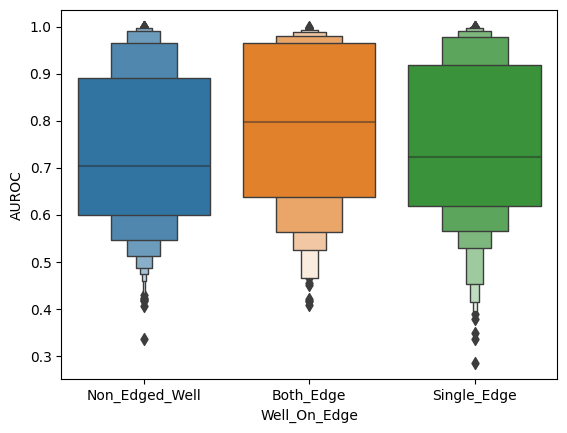

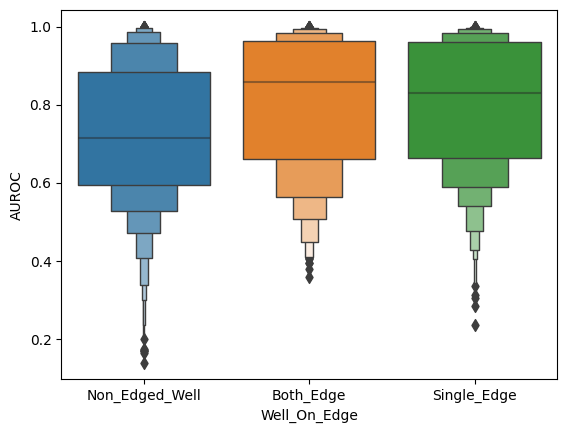

In [130]:
profiled_classifiers_df_non_ctrl = profiled_prot_classifiers_df.filter(
    ~pl.col("Metadata_Control")
).with_columns(
    pl.when((pl.col("well_0").str.contains(r"(?:01|P|A|24)"))&(pl.col("well_1").str.contains(r"(?:01|P|A|24)")))
    .then(pl.lit("Both_Edge"))
    .when((pl.col("well_0").str.contains(r"(?:01|P|A|24)"))|(pl.col("well_1").str.contains(r"(?:01|P|A|24)")))
    .then(pl.lit("Single_Edge"))
    .otherwise(pl.lit("Non_Edged_Well"))
    .alias("Well_On_Edge")
)
sns.boxenplot(data=profiled_classifiers_df_non_ctrl.to_pandas(), x="Well_On_Edge", y="AUROC")
plt.show()

profiled_classifiers_df_non_ctrl = profiled_morph_classifiers_df.filter(
    ~pl.col("Metadata_Control")
).with_columns(
    pl.when((pl.col("well_0").str.contains(r"(?:01|P|A|24)"))&(pl.col("well_1").str.contains(r"(?:01|P|A|24)")))
    .then(pl.lit("Both_Edge"))
    .when((pl.col("well_0").str.contains(r"(?:01|P|A|24)"))|(pl.col("well_1").str.contains(r"(?:01|P|A|24)")))
    .then(pl.lit("Single_Edge"))
    .otherwise(pl.lit("Non_Edged_Well"))
    .alias("Well_On_Edge")
)
sns.boxenplot(data=profiled_classifiers_df_non_ctrl.to_pandas(), x="Well_On_Edge", y="AUROC")
plt.show()

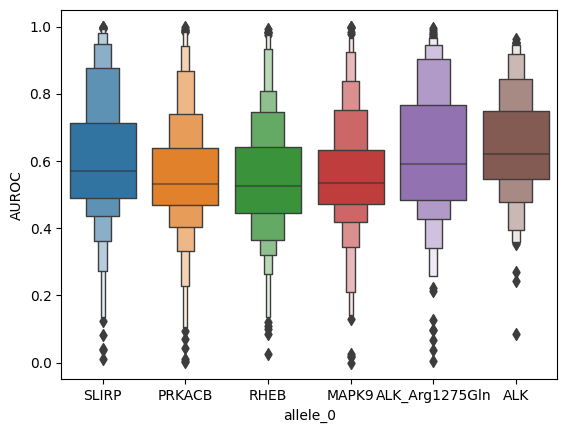

In [22]:
profiled_classifiers_df_ctrl = profiled_classifiers_df.filter(
    pl.col("Metadata_Control") & ~(pl.col("Classifier_ID").str.contains("B11") | pl.col("Classifier_ID").str.contains("B12"))
)
profiled_classifiers_df_ctrl["allele_0"].unique()
sns.boxenplot(data=profiled_classifiers_df_ctrl.to_pandas(), x="allele_0", y="AUROC")
plt.show()

In [52]:
# Paths
pass_qc_prof_pq_path = "../outputs/batch_profiles/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"
ref_var_cell_qc_profile_df = pl.DataFrame()

# Get meta features
for batch_id in BATCH_LIST_DICT.keys():
    batch_alleles = (
        pl.scan_parquet(
            pass_qc_prof_pq_path.format(batch_id=batch_id)
        )
        .filter(pl.col("Metadata_gene_allele").is_in(profiled_ctrls_df["gene_allele"].unique()))
        .with_columns(
            pl.concat_str(
                [
                    "Metadata_Plate",
                    "Metadata_Well",
                    "Metadata_ImageNumber",
                    "Metadata_ObjectNumber",
                ],
                separator="_",
            ).alias("Metadata_CellID")
        )
        .select([
            "Metadata_CellID",
            "Metadata_gene_allele",
            "Metadata_Well",
            "Metadata_Plate",
            "Metadata_node_type"
        ])
    )
    ref_var_cell_qc_profile_df = pl.concat([ref_var_cell_qc_profile_df, batch_alleles.collect()])

In [53]:
# Paths
prof_pq_path = "../outputs/batch_profiles/{batch_id}/profiles.parquet"
ref_var_cell_all_profiles = {}

# Get meta features
for batch_id in BATCH_LIST_DICT.keys():
    batch_alleles = (
        pl.scan_parquet(
            prof_pq_path.format(batch_id=batch_id)
        )
        .filter(pl.col("Metadata_gene_allele").is_in(profiled_ctrls_df["gene_allele"].unique()))
        .with_columns(
            pl.concat_str(
                [
                    "Metadata_Plate",
                    "Metadata_Well",
                    "Metadata_ImageNumber",
                    "Metadata_ObjectNumber",
                ],
                separator="_",
            ).alias("Metadata_CellID")
        )
    )
    ref_var_cell_all_profiles[batch_id] = batch_alleles

In [54]:
gfp_feats = [i for i in list(ref_var_cell_all_profiles.values())[0].collect_schema() if "GFP" in i and "Brightfield" not in i]
gfp_feats = ["Metadata_CellID"] + gfp_feats

ref_var_cell_all_gfp_profiles_df = pl.concat([batch_alleles[1].select(gfp_feats).collect() for batch_alleles in ref_var_cell_all_profiles.items()])
# This method of joining ensures that only cells past filters are included in the abundance analysis
ref_var_cell_gfp_profile_df = ref_var_cell_qc_profile_df.join(ref_var_cell_all_gfp_profiles_df, on="Metadata_CellID", how="left")

morph_feats = [i for i in list(ref_var_cell_all_profiles.values())[2].collect_schema() if ("DNA" in i or "Mito" in i or "AGP" in i) and "Brightfield" not in i]
morph_feats = ["Metadata_CellID"] + morph_feats

ref_var_cell_all_morph_profiles_df = pl.concat([batch_alleles[1].select(morph_feats).collect() for batch_alleles in ref_var_cell_all_profiles.items() if "Batch_7" not in batch_alleles[0] and "Batch_8" not in batch_alleles[0]])
# This method of joining ensures that only cells past filters are included in the abundance analysis
ref_var_cell_morph_profile_df = ref_var_cell_qc_profile_df.join(ref_var_cell_all_morph_profiles_df, on="Metadata_CellID", how="inner")

In [56]:
ref_var_cell_morph_profile_df.filter(pl.col("Metadata_gene_allele")=="RHEB")

Metadata_CellID,Metadata_gene_allele,Metadata_Well,Metadata_Plate,Metadata_node_type,Cytoplasm_Correlation_Correlation_AGP_DNA,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_AGP_Mito,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_DNA_Mito,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_DNA,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_AGP_Mito,Cytoplasm_Correlation_Costes_DNA_AGP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_DNA_Mito,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_AGP,Cytoplasm_Correlation_Costes_Mito_DNA,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_DNA,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_AGP_Mito,Cytoplasm_Correlation_K_DNA_AGP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_DNA_Mito,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_DNA,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_Mito_AGP,Cytoplasm_Correlation_K_Mito_DNA,Cytoplasm_Correlation_K_Mito_GFP,Cytoplasm_Correlation_Manders_AGP_DNA,Cytoplasm_Correlation_Manders_AGP_GFP,…,Nuclei_Texture_SumVariance_Mito_5_03_256,Nuclei_Texture_Variance_AGP_10_00_256,Nuclei_Texture_Variance_AGP_10_01_256,Nuclei_Texture_Variance_AGP_10_02_256,Nuclei_Texture_Variance_AGP_10_03_256,Nuclei_Texture_Variance_AGP_20_00_256,Nuclei_Texture_Variance_AGP_20_01_256,Nuclei_Texture_Variance_AGP_20_02_256,Nuclei_Texture_Variance_AGP_20_03_256,Nuclei_Texture_Variance_AGP_5_00_256,Nuclei_Texture_Variance_AGP_5_01_256,Nuclei_Texture_Variance_AGP_5_02_256,Nuclei_Texture_Variance_AGP_5_03_256,Nuclei_Texture_Variance_DNA_10_00_256,Nuclei_Texture_Variance_DNA_10_01_256,Nuclei_Texture_Variance_DNA_10_02_256,Nuclei_Texture_Variance_DNA_10_03_256,Nuclei_Texture_Variance_DNA_20_00_256,Nuclei_Texture_Variance_DNA_20_01_256,Nuclei_Texture_Variance_DNA_20_02_256,Nuclei_Texture_Variance_DNA_20_03_256,Nuclei_Texture_Variance_DNA_5_00_256,Nuclei_Texture_Variance_DNA_5_01_256,Nuclei_Texture_Variance_DNA_5_02_256,Nuclei_Texture_Variance_DNA_5_03_256,Nuclei_Texture_Variance_Mito_10_00_256,Nuclei_Texture_Variance_Mito_10_01_256,Nuclei_Texture_Variance_Mito_10_02_256,Nuclei_Texture_Variance_Mito_10_03_256,Nuclei_Texture_Variance_Mito_20_00_256,Nuclei_Texture_Variance_Mito_20_01_256,Nuclei_Texture_Variance_Mito_20_02_256,Nuclei_Texture_Variance_Mito_20_03_256,Nuclei_Texture_Variance_Mito_5_00_256,Nuclei_Texture_Variance_Mito_5_01_256,Nuclei_Texture_Variance_Mito_5_02_256,Nuclei_Texture_Variance_Mito_5_03_256
str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""2024-12-09_B11A1R1_J15_2076_1""","""RHEB""","""J15""","""2024-12-09_B11A1R1""","""NC""",0.23422,0.509356,0.243331,0.492616,0.533717,0.814679,0.252351,1.0,1.0,0.982918,1.0,0.941096,1.0,0.103397,0.685339,1.0,0.726281,1.0,0.179281,0.878928,0.983948,4.902965,4.763063,5.146097,0.957555,0.182762,0.980171,0.715663,0.15316,0.909363,1.0,0.94334,…,5.341007,0.594787,0.614164,0.627185,0.640409,0.732141,0.519047,0.476648,0.678392,0.582176,0.539563,0.588132,0.587517,0.690857,0.633333,0.676224,0.67535,0.860333,0.583974,0.769788,1.115892,0.633856,0.582128,0.639134,0.652891,2.577315,2.254035,2.4027,2.467496,2.80846,3.385813,3.378978,5.5739,2.591562,2.220838,2.322062,2.143375
"""2024-12-09_B11A1R1_J15_2077_1""","""RHEB""","""J15""","""2024-12-09_B11A1R1""","""NC""",0.155904,0.053096,0.095051,-0.003645,0.37218,0.231542,0.381302,1.0,1.0,0.995149,1.0,1.0,1.0,1.0,0.998722,1.0,1.0,1.0,0.19708,0.91051,8.129567,4.36838,4.293804,31.03571,0.76891,0.167652,12.298219,0.101257,0.026897,0.063018,1.0,0.936562,…,2.249016,0.416726,0.427571,0.373725,0

In [64]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import rankdata, norm
import umap


def inverse_normal_transform(x):
    ranks = rankdata(x, method="average")
    return norm.ppf((ranks - 0.5) / len(ranks))


# Define INT function for a single column
def inverse_normal_transform_series(series: pl.Series) -> pl.Series:
    values = series #.to_numpy()
    ranks = rankdata(values, method="average")
    n = len(ranks)
    transformed = norm.ppf((ranks - 0.5) / n)
    return pl.Series(series.name, transformed)


def int_num_cols(df):
    # 2) pick the columns you want to INT (here all numeric columns)
    num_cols = [
        name
        for name, dtype in df.schema.items()
        if "Metadata_" not in name
    ]

    # 3) for each numeric column, pull out a numpy array, compute the INT, and wrap back
    transforms = []
    for col in num_cols:
        arr = df[col].to_numpy()
        ranks = rankdata(arr, method="average")
        quantiles = (ranks - 0.5) / len(arr)
        transformed = norm.ppf(quantiles)
        transforms.append(pl.Series(col, transformed))

    # 4) build a new DataFrame of the transformed columns
    df_int = pl.DataFrame(transforms)
    # print(df_int)

    # 5) you can then concat non-numeric columns back if needed:
    non_num = df.select(pl.exclude(num_cols))
    df_norm = non_num.hstack(df_int)
    return df_norm
    

def remove_corr_feats(df, corr_thres=.8):
    # 2. Identify numeric columns
    all_num_feats = [
        name
        for name, dtype in df.schema.items()
        if dtype in (pl.Int8, pl.Int16, pl.Int32, pl.Int64, pl.Float32, pl.Float64)
    ]
    # 3. Bring that slice into pandas
    pdf = df.select(all_num_feats).to_pandas()
    # 4. Compute absolute correlation matrix
    corr = pdf.corr().abs()
    # 5. Mask out the lower triangle (we only need one side)
    upper = corr.where(
        np.triu(np.ones(corr.shape), k=1).astype(bool)
    )
    # 6. Pick columns to drop: any column with correlation > threshold to *any* other
    to_drop = [col for col in upper.columns if any(upper[col] > corr_thres)]
    # 7. Drop them in your original Polars DF
    df_drop_corr_cols = df.drop(to_drop)

    return df_drop_corr_cols


def plot_dr(df, dr_method, standardize=True, ax=None, dr_args={}, plot_args={}):
    df_val = df.select(pl.col([col for col in df.columns if not col.startswith("Metadata_")]))#.drop_nulls()
    if standardize:
        # Standardize the features before PCA
        scaler = StandardScaler()
        df_val = pd.DataFrame(scaler.fit_transform(df_val), columns=df_val.columns)

    if dr_method=="pca":
        pca = PCA(**dr_args) #n_components=10
        dr_result = pca.fit_transform(df_val)
    if dr_method=="umap":
        # Perform UMAP
        umap_model = umap.UMAP(**dr_args) ## n_neighbors=15, min_dist=0.1, n_components=2, random_state=42, n_jobs=1
        dr_result = umap_model.fit_transform(df_val.to_numpy())

    dr_res_df = pd.DataFrame(dr_result, columns=[f"Comp{i+1}" for i in range(dr_result.shape[1])])
    for key in ["hue", "style", "size"]:
        if key in plot_args and plot_args[key] in df.columns:
            dr_res_df[plot_args[key]] = df[plot_args[key]].to_numpy()

    if ax is None:
        # Plot UMAP
        fig, ax = plt.subplots(1, 1, figsize=(6, 7))

    # print(len(dr_res_df[plot_args["hue"]].unique()))
    if "palette" not in plot_args:
        sns.scatterplot(data=dr_res_df.sort_values(by=plot_args["hue"]),
                        x="Comp1", y="Comp2",
                        palette=sns.color_palette("husl", len(dr_res_df.dropna(subset=plot_args["hue"])[plot_args["hue"]].unique())),#, 
                        ax=ax, **plot_args) ##  alpha=.5, s=40
    else:
        sns.scatterplot(data=dr_res_df.sort_values(by=plot_args["hue"]),
                        x="Comp1", y="Comp2",
                        ax=ax, **plot_args) ##  alpha=.5, s=40
    # plt.show()
    # ax[1].legend(ncol=2, title="Metadata_Batch")
    return dr_res_df

In [59]:
ref_var_well_morph_profile_df = (
    ref_var_cell_morph_profile_df.group_by(["Metadata_Plate", "Metadata_Well", "Metadata_gene_allele"])
    .agg(
        pl.col(col).median().alias(col)
        for col in ref_var_cell_morph_profile_df.columns
        if not col.startswith("Metadata_")
    )
    .unique()
    .drop_nulls("Metadata_gene_allele")
)

ref_var_well_morph_profile_df = ref_var_well_morph_profile_df.with_columns(
    pl.col("Metadata_Plate")
      # capture a “B” followed by any non-underscore chars up to the first “A”
      .str.extract(r"(B[^_]*?A)", 1)
      .alias("Metadata_Batch")
).drop_nulls()

ref_var_well_morph_profile_df = remove_corr_feats(ref_var_well_morph_profile_df)
ref_var_well_morph_profile_df

Metadata_Plate,Metadata_Well,Metadata_gene_allele,Cytoplasm_Correlation_Correlation_AGP_DNA,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_AGP_Mito,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_DNA_Mito,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_DNA,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_AGP_Mito,Cytoplasm_Correlation_Costes_DNA_AGP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_DNA_Mito,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_AGP,Cytoplasm_Correlation_Costes_Mito_DNA,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_DNA,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_AGP_Mito,Cytoplasm_Correlation_K_DNA_Mito,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_Mito_AGP,Cytoplasm_Correlation_Manders_AGP_DNA,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Correlation_Manders_AGP_Mito,Cytoplasm_Correlation_Manders_DNA_AGP,Cytoplasm_Correlation_Manders_GFP_AGP,Cytoplasm_Correlation_Manders_GFP_Mito,Cytoplasm_Correlation_Manders_Mito_AGP,Cytoplasm_Correlation_Overlap_AGP_DNA,Cytoplasm_Correlation_Overlap_AGP_GFP,Cytoplasm_Correlation_Overlap_AGP_Mito,…,Nuclei_RadialDistribution_FracAtD_AGP_10of10,Nuclei_RadialDistribution_FracAtD_AGP_1of10,Nuclei_RadialDistribution_FracAtD_AGP_2of10,Nuclei_RadialDistribution_FracAtD_AGP_8of10,Nuclei_RadialDistribution_FracAtD_AGP_9of10,Nuclei_RadialDistribution_FracAtD_DNA_1of10,Nuclei_RadialDistribution_FracAtD_DNA_8of10,Nuclei_RadialDistribution_FracAtD_Mito_10of10,Nuclei_RadialDistribution_FracAtD_Mito_1of10,Nuclei_RadialDistribution_FracAtD_Mito_8of10,Nuclei_RadialDistribution_MeanFrac_AGP_9of10,Nuclei_RadialDistribution_RadialCV_AGP_10of10,Nuclei_RadialDistribution_RadialCV_AGP_1of10,Nuclei_RadialDistribution_RadialCV_AGP_2of10,Nuclei_RadialDistribution_RadialCV_AGP_3of10,Nuclei_RadialDistribution_RadialCV_DNA_1of10,Nuclei_RadialDistribution_RadialCV_Mito_1of10,Nuclei_Texture_Correlation_AGP_10_00_256,Nuclei_Texture_Correlation_AGP_10_01_256,Nuclei_Texture_Correlation_AGP_10_02_256,Nuclei_Texture_Correlation_AGP_10_03_256,Nuclei_Texture_Correlation_AGP_20_00_256,Nuclei_Texture_Correlation_AGP_20_01_256,Nuclei_Texture_Correlation_AGP_20_02_256,Nuclei_Texture_Correlation_AGP_20_03_256,Nuclei_Texture_Correlation_AGP_5_00_256,Nuclei_Texture_Correlation_AGP_5_01_256,Nuclei_Texture_Correlation_AGP_5_02_256,Nuclei_Texture_Correlation_AGP_5_03_256,Nuclei_Texture_Correlation_DNA_10_00_256,Nuclei_Texture_Correlation_DNA_10_02_256,Nuclei_Texture_Correlation_DNA_5_00_256,Nuclei_Texture_Correlation_Mito_10_00_256,Nuclei_Texture_Correlation_Mito_20_01_256,Nuclei_Texture_Correlation_Mito_20_03_256,Nuclei_Texture_InfoMeas1_Mito_5_00_256,Metadata_Batch
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""2025-03-17_B15A1A2_P1T2""","""H18""","""SLIRP""",0.1973,0.16826,0.255505,0.390637,0.334098,0.880526,0.195793,1.0,0.973842,0.996794,1.0,1.0,1.0,1.0,0.751755,0.999876,1.0,1.0,0.163583,0.399236,0.75038,4.505827,1.810452,1.008928,1.0,0.494506,0.964709,0.979109,0.999076,1.0,0.994094,0.946238,0.858403,0.873019,…,0.199477,0.005862,0.016683,0.169982,0.215743,0.007241,0.177214,0.218427,0.006282,0.158377,1.037902,0.196918,0.047327,0.070383,0.078511,0.046333,0.024083,0.047103,-0.039162,0.035435,-0.051187,-0.004563,-0.030081,-0.015467,-0.050496,0.283531,0.158339,0.279748,0.13723,-0.007588,-0.001692,0.125991,0.117349,-0.108892,-0.072201,-0.110781,"""B15A"""
"""2025-03-17_B15A1A2_P1T4""","""J10""","""ALK_Arg1275Gln""",0.273805,0.255491,0.39201,0.158867,0.367243,0.322053,0.307087,0.586709,0.991996,0.990816,0.925158

In [60]:
ref_var_well_morph_profile_int_df = int_num_cols(ref_var_well_morph_profile_df)

<Figure size 640x480 with 0 Axes>

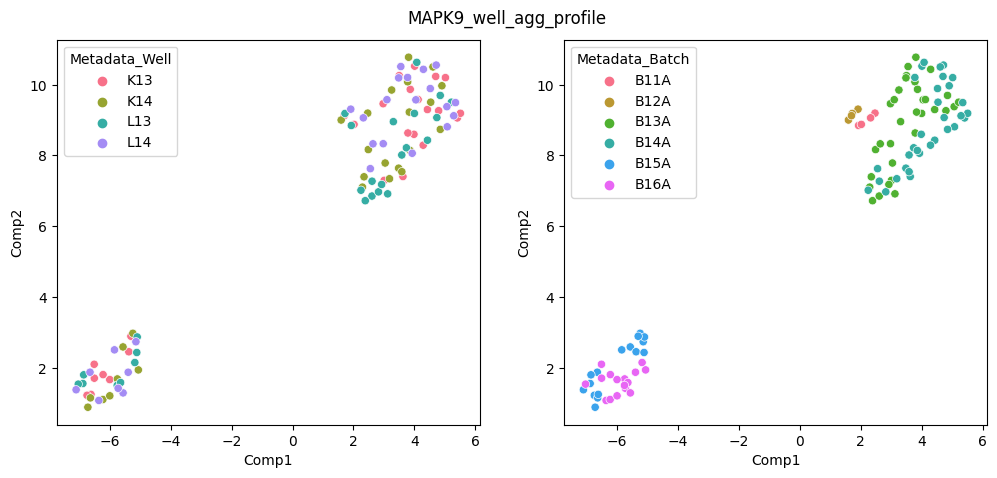

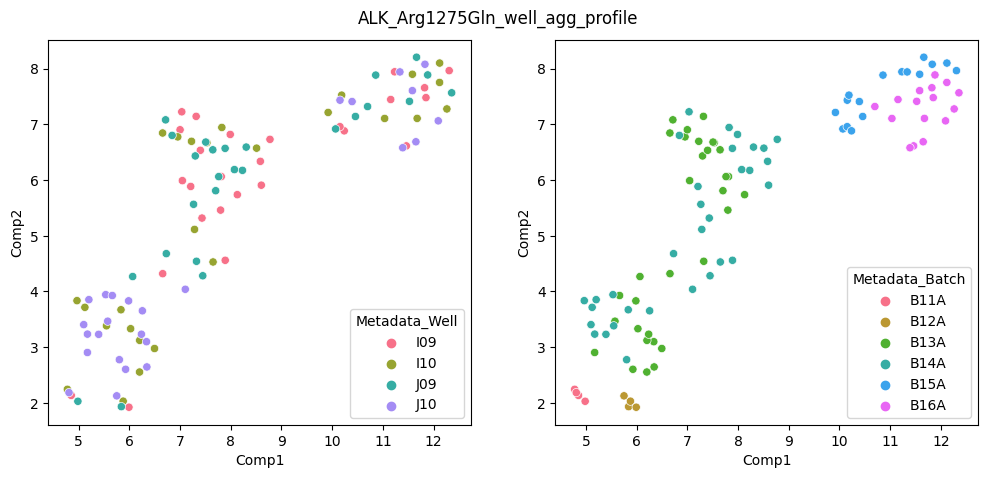

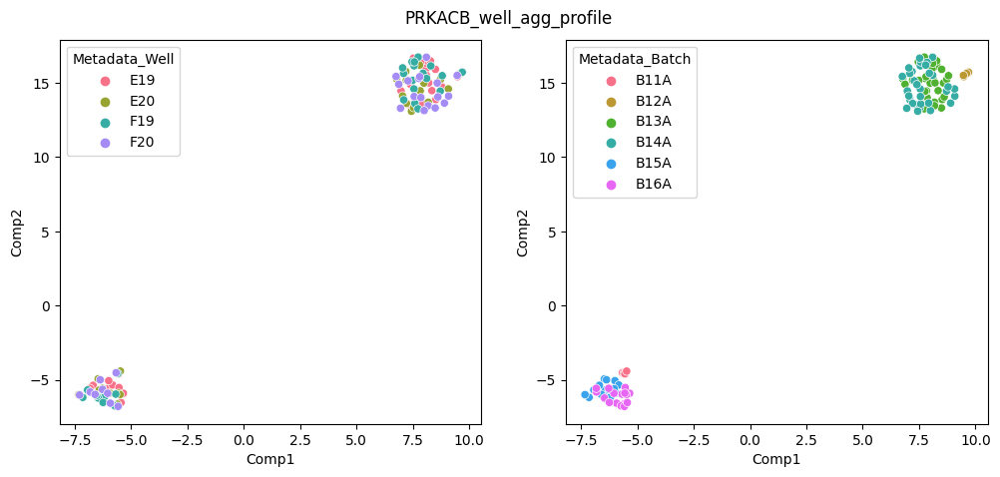

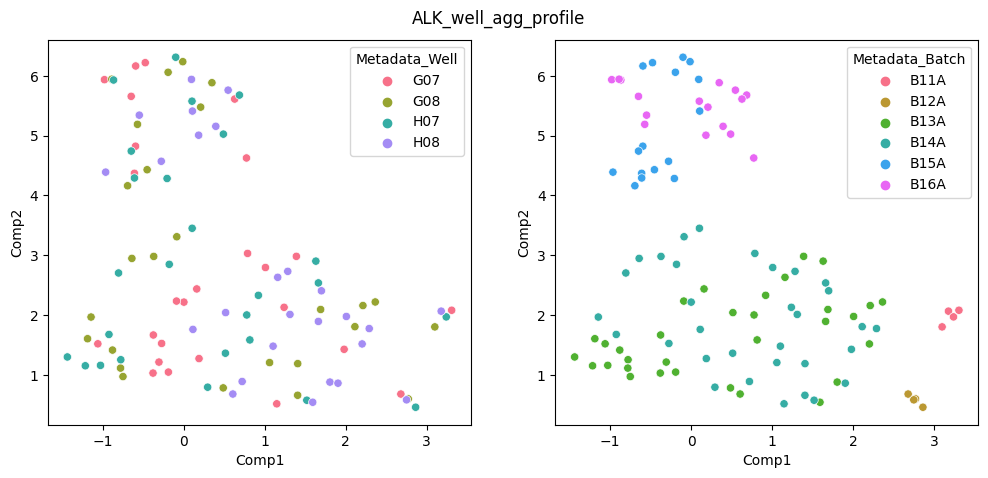

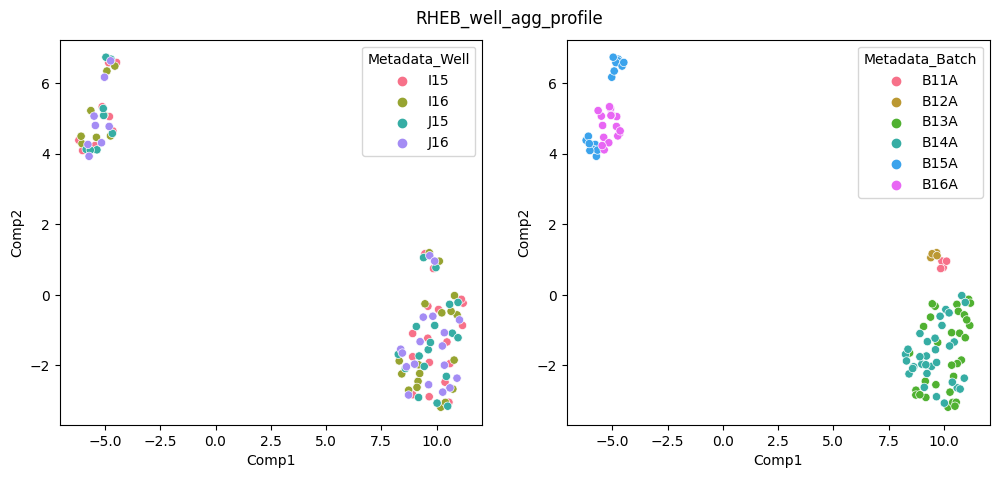

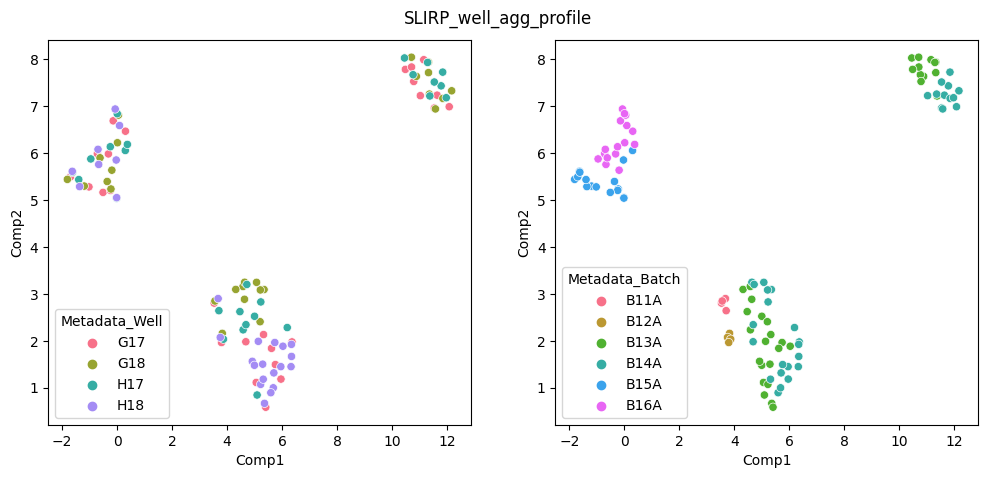

In [70]:
plt.clf()
for gene_allele in ref_var_well_morph_profile_int_df["Metadata_gene_allele"].unique():
    # print(gene_allele)
    ref_var_well_morph_profile_int_df_allele = ref_var_well_morph_profile_int_df.filter(pl.col("Metadata_gene_allele")==gene_allele)
    fig, axes = plt.subplots(1,2,figsize=(12,5))
    plot_dr(ref_var_well_morph_profile_int_df_allele, "umap", standardize=False, dr_args={"random_state":42, "n_jobs": 1},
                          plot_args={"hue": "Metadata_Well"}, ax=axes[0])
    plot_dr(ref_var_well_morph_profile_int_df_allele, "umap", standardize=False, dr_args={"random_state":42, "n_jobs": 1},
                          plot_args={"hue": "Metadata_Batch"}, ax=axes[1])
    plt.suptitle(f"{gene_allele}_well_agg_profile",y=.94)
    plt.show()